# IBD - Lab 9
## Clustering con todas las características, PCA y evaluación en test set

**Versión preparada para Google Colab.**

En este laboratorio vamos a trabajar con el dataset **Breast Cancer Wisconsin Diagnostic**. El objetivo es aprender a:

1. Construir un vector de características usando **todas las variables disponibles**.
2. Dividir los datos en **training set** y **test set**.
3. Entrenar **K-Means** con el training set.
4. Evaluar el clustering usando el **test set**.
5. Aplicar **PCA** para reducir la dimensionalidad.
6. Buscar el mejor valor de **k** y comparar los resultados antes y después de PCA.


## 1. Configuración para Google Colab

Ejecuta esta celda primero. Instala PySpark en Google Colab.


In [ ]:
# Google Colab setup
%pip -q install pyspark==3.5.1


Importamos las librerías necesarias y creamos la sesión de Spark.


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml.feature import VectorAssembler, StandardScaler, PCA
from pyspark.ml.clustering import KMeans
from pyspark.ml.evaluation import ClusteringEvaluator

spark = (
    SparkSession.builder
    .appName("IBD_Lab_9_KMeans_PCA_Colab")
    .master("local[*]")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")
print("Spark version:", spark.version)


Spark version: 3.5.1


## 2. Cargar el dataset

Usaremos el dataset **Breast Cancer Wisconsin Diagnostic**.

Cada fila representa una muestra médica. Cada muestra tiene **30 características numéricas**. En este laboratorio usaremos todas las características para hacer clustering.

La columna `label` se conserva solo para comparar de forma informativa los clústeres con las clases reales. K-Means no usa esta columna durante el entrenamiento.


In [ ]:
data = load_breast_cancer()

pd_df = pd.DataFrame(data.data, columns=data.feature_names)
pd_df["label"] = data.target

print("Target names:", data.target_names)
print("Number of samples:", pd_df.shape[0])
print("Number of original features:", len(data.feature_names))
pd_df.head()


Target names: ['malignant' 'benign']
Number of samples: 569
Number of original features: 30


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,label
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [ ]:
df = spark.createDataFrame(pd_df)

print("Rows:", df.count())
print("Columns:", len(df.columns))
df.select("label").groupBy("label").count().show()


Rows: 569
Columns: 31
+-----+-----+
|label|count|
+-----+-----+
|    0|  212|
|    1|  357|
+-----+-----+



## 3. Construir el vector con todas las características

MLlib necesita una única columna vectorial para entrenar los modelos. Por eso usamos `VectorAssembler` para combinar las 30 características originales en una columna llamada `features_raw`.


In [ ]:
feature_cols = list(data.feature_names)

assembler = VectorAssembler(
    inputCols=feature_cols,
    outputCol="features_raw"
)

df_features = assembler.transform(df).select("features_raw", "label")

print("Number of features used for clustering:", len(feature_cols))
df_features.show(3, truncate=False)


Number of features used for clustering: 30
+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-----+
|features_raw                                                                                                                                                                                                        |label|
+--------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-----+
|[17.99,10.38,122.8,1001.0,0.1184,0.2776,0.3001,0.1471,0.2419,0.07871,1.095,0.9053,8.589,153.4,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193,25.38,17.33,184.6,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.1189] |0    |
|[20.57,17.77,132.9,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,

## 4. Dividir los datos en training set y test set

Para evaluar correctamente, dividimos los datos antes de entrenar K-Means:

- **80% training set**: se usa para entrenar K-Means.
- **20% test set**: se usa para evaluar el modelo entrenado.

Esto nos permite comprobar si los clústeres generalizan bien a datos no usados durante el entrenamiento.


In [ ]:
train_df, test_df = df_features.randomSplit([0.8, 0.2], seed=42)

print("Training rows:", train_df.count())
print("Test rows:", test_df.count())


Training rows: 474
Test rows: 95


## 5. Normalizar las características

K-Means depende de las distancias. Si una característica tiene valores muy grandes, puede dominar el cálculo de la distancia.

Por eso aplicamos `StandardScaler`.

Importante: el scaler se ajusta solo con el **training set** y después se aplica al **test set**.


In [ ]:
scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="features",
    withMean=True,
    withStd=True
)

scaler_model = scaler.fit(train_df)
train_scaled = scaler_model.transform(train_df).select("features", "label")
test_scaled = scaler_model.transform(test_df).select("features", "label")

train_scaled.show(3, truncate=False)


+------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-----+
|features                                                                                                                                                                                                                                                                                                                                                                                                    

## 6. Funciones auxiliares para entrenar y evaluar K-Means

La evaluación principal será el **Silhouette score** calculado sobre el **test set**.

- Valor cercano a 1: clústeres bien separados.
- Valor cercano a 0: clústeres solapados.
- Valor negativo: puntos probablemente asignados a clústeres incorrectos.


In [ ]:
def fit_kmeans_and_evaluate(train_data, test_data, features_col="features", k=2, seed=42):
    """
    Train K-Means on the training set and evaluate it on the test set.
    Returns the trained model, test predictions, and test Silhouette score.
    """
    kmeans = KMeans(
        featuresCol=features_col,
        predictionCol="prediction",
        k=k,
        seed=seed
    )
    model = kmeans.fit(train_data)
    test_predictions = model.transform(test_data)

    evaluator = ClusteringEvaluator(
        featuresCol=features_col,
        predictionCol="prediction",
        metricName="silhouette",
        distanceMeasure="squaredEuclidean"
    )
    silhouette = evaluator.evaluate(test_predictions)
    return model, test_predictions, silhouette


def evaluate_k_values(train_data, test_data, features_col="features", k_values=range(2, 11), seed=42):
    """
    Try several values of k. For each k, train on training set and evaluate on test set.
    """
    rows = []
    for k in k_values:
        _, _, sil = fit_kmeans_and_evaluate(
            train_data=train_data,
            test_data=test_data,
            features_col=features_col,
            k=k,
            seed=seed
        )
        rows.append({"k": k, "test_silhouette": sil})
    return pd.DataFrame(rows)


def show_cluster_label_distribution(predictions):
    """
    Optional external analysis: compare clusters with true labels.
    This is not used by K-Means, but helps us understand the clusters.
    """
    # The column name for the actual target labels is 'target_binary' for the heart disease dataset.
    return (
        predictions
        .groupBy("prediction", "target_binary")
        .count()
        .orderBy("prediction", "target_binary")
    )

## 7. K-Means usando todas las características originales

Primero entrenamos K-Means usando las **30 características originales normalizadas**.

Empezamos con `k = 2` porque el dataset tiene dos clases reales, pero recuerda que K-Means no usa las etiquetas.


In [ ]:
model_all_k2, test_pred_all_k2, sil_all_k2 = fit_kmeans_and_evaluate(
    train_data=train_scaled,
    test_data=test_scaled,
    features_col="features",
    k=2,
    seed=42
)

print(f"Test Silhouette score using all 30 features and k=2: {sil_all_k2:.4f}")
show_cluster_label_distribution(test_pred_all_k2).show()


Test Silhouette score using all 30 features and k=2: 0.5203
+----------+-----+-----+
|prediction|label|count|
+----------+-----+-----+
|         0|    0|   25|
|         0|    1|    1|
|         1|    0|    5|
|         1|    1|   64|
+----------+-----+-----+



## 8. Buscar el mejor valor de k usando todas las características

Ahora probamos varios valores de `k`. Para cada valor:

1. Entrenamos K-Means con el training set.
2. Evaluamos el modelo con el test set.
3. Guardamos el Silhouette score.


In [ ]:
k_values = range(2, 11)
results_all_features = evaluate_k_values(
    train_data=train_scaled,
    test_data=test_scaled,
    features_col="features",
    k_values=k_values,
    seed=42
)

best_all = results_all_features.loc[results_all_features["test_silhouette"].idxmax()]
print("Results using all 30 features:")
display(results_all_features)
print(f"Best k using all features: k = {int(best_all['k'])}, test silhouette = {best_all['test_silhouette']:.4f}")


Results using all 30 features:


,k,test_silhouette
0,2,0.520267
1,3,0.486982
2,4,0.464157
3,5,0.362597
4,6,0.245985
5,7,0.245434
6,8,0.185138
7,9,0.163459
8,10,0.166241


Best k using all features: k = 2, test silhouette = 0.5203


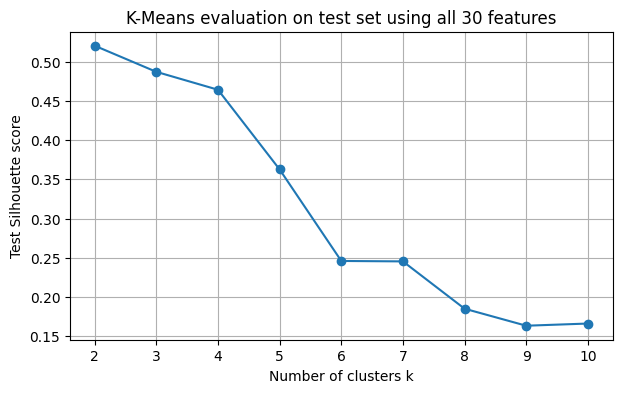

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(results_all_features["k"], results_all_features["test_silhouette"], marker="o")
plt.xlabel("Number of clusters k")
plt.ylabel("Test Silhouette score")
plt.title("K-Means evaluation on test set using all 30 features")
plt.grid(True)
plt.show()


## 9. PCA: reducir la dimensionalidad

El dataset original tiene 30 características. PCA permite transformar estas características en un número menor de componentes principales.

La idea es conservar la mayor parte de la información, pero usando menos dimensiones.

Importante: igual que antes, PCA se ajusta usando solo el **training set** y después se aplica al **test set**.


In [ ]:
# Example: reduce from 30 original features to 2 principal components
pca_2 = PCA(
    k=2,
    inputCol="features",
    outputCol="pcaFeatures"
)

pca_2_model = pca_2.fit(train_scaled)
train_pca_2 = pca_2_model.transform(train_scaled).select("pcaFeatures", "label")
test_pca_2 = pca_2_model.transform(test_scaled).select("pcaFeatures", "label")

print("Explained variance ratio for the two PCA components:")
print(pca_2_model.explainedVariance)
print("Total explained variance:", float(sum(pca_2_model.explainedVariance)))

train_pca_2.show(3, truncate=False)


Explained variance ratio for the two PCA components:
[0.4470095769334713,0.18458731059861685]
Total explained variance: 0.6315968875320882
+----------------------------------------+-----+
|pcaFeatures                             |label|
+----------------------------------------+-----+
|[4.648320710100684,-3.579924120011284]  |1    |
|[4.6856509752869835,-1.4767364275024168]|1    |
|[2.656458170766136,-3.206111385302964]  |1    |
+----------------------------------------+-----+
only showing top 3 rows



## 10. Visualizar los datos después de PCA

Con 2 componentes principales podemos representar los datos en 2D.


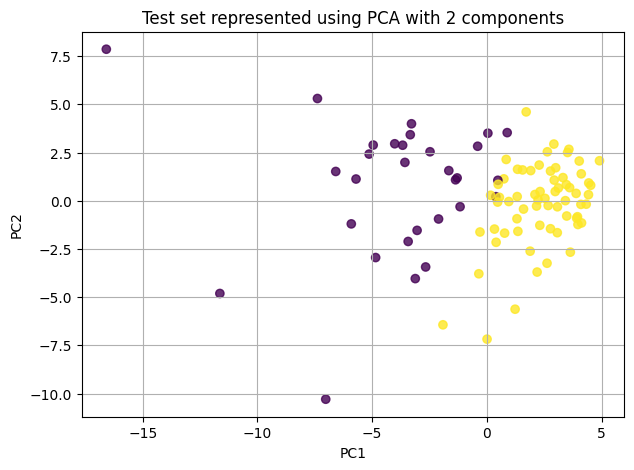

In [ ]:
pca_test_pdf = test_pca_2.select("pcaFeatures", "label").toPandas()
pca_test_pdf["PC1"] = pca_test_pdf["pcaFeatures"].apply(lambda v: float(v[0]))
pca_test_pdf["PC2"] = pca_test_pdf["pcaFeatures"].apply(lambda v: float(v[1]))

plt.figure(figsize=(7, 5))
plt.scatter(pca_test_pdf["PC1"], pca_test_pdf["PC2"], c=pca_test_pdf["label"], alpha=0.8)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Test set represented using PCA with 2 components")
plt.grid(True)
plt.show()


## 11. K-Means después de PCA

Ahora entrenamos K-Means usando las características reducidas por PCA.

Aquí usamos `pcaFeatures` en lugar de `features`.


In [ ]:
model_pca2_k2, test_pred_pca2_k2, sil_pca2_k2 = fit_kmeans_and_evaluate(
    train_data=train_pca_2,
    test_data=test_pca_2,
    features_col="pcaFeatures",
    k=2,
    seed=42
)

print(f"Test Silhouette score using PCA with 2 components and k=2: {sil_pca2_k2:.4f}")
show_cluster_label_distribution(test_pred_pca2_k2).show()


Test Silhouette score using PCA with 2 components and k=2: 0.6504
+----------+-----+-----+
|prediction|label|count|
+----------+-----+-----+
|         0|    0|   25|
|         0|    1|    1|
|         1|    0|    5|
|         1|    1|   64|
+----------+-----+-----+



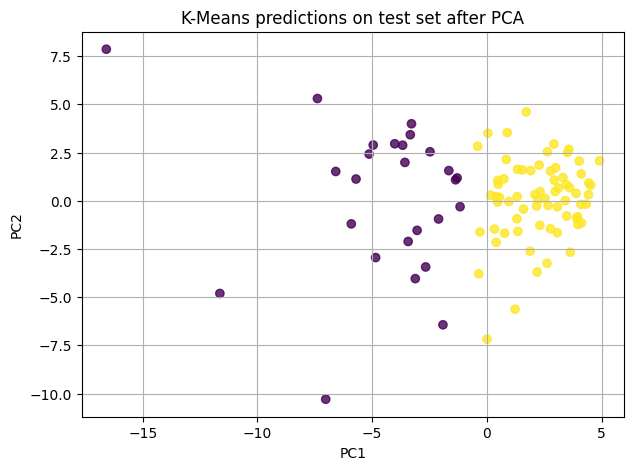

In [ ]:
# Visualize clusters predicted by K-Means after PCA
pred_pca_pdf = test_pred_pca2_k2.select("pcaFeatures", "prediction", "label").toPandas()
pred_pca_pdf["PC1"] = pred_pca_pdf["pcaFeatures"].apply(lambda v: float(v[0]))
pred_pca_pdf["PC2"] = pred_pca_pdf["pcaFeatures"].apply(lambda v: float(v[1]))

plt.figure(figsize=(7, 5))
plt.scatter(pred_pca_pdf["PC1"], pred_pca_pdf["PC2"], c=pred_pca_pdf["prediction"], alpha=0.8)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("K-Means predictions on test set after PCA")
plt.grid(True)
plt.show()


## 12. Buscar el mejor k después de PCA

Repetimos la búsqueda del mejor valor de `k`, pero ahora usando las características reducidas por PCA.


In [ ]:
results_pca_2 = evaluate_k_values(
    train_data=train_pca_2,
    test_data=test_pca_2,
    features_col="pcaFeatures",
    k_values=range(2, 11),
    seed=42
)

best_pca_2 = results_pca_2.loc[results_pca_2["test_silhouette"].idxmax()]
print("Results using PCA with 2 components:")
display(results_pca_2)
print(f"Best k after PCA with 2 components: k = {int(best_pca_2['k'])}, test silhouette = {best_pca_2['test_silhouette']:.4f}")


Results using PCA with 2 components:


,k,test_silhouette
0,2,0.650358
1,3,0.638204
2,4,0.451631
3,5,0.452975
4,6,0.433553
5,7,0.506503
6,8,0.411599
7,9,0.402260
8,10,0.405695


Best k after PCA with 2 components: k = 2, test silhouette = 0.6504


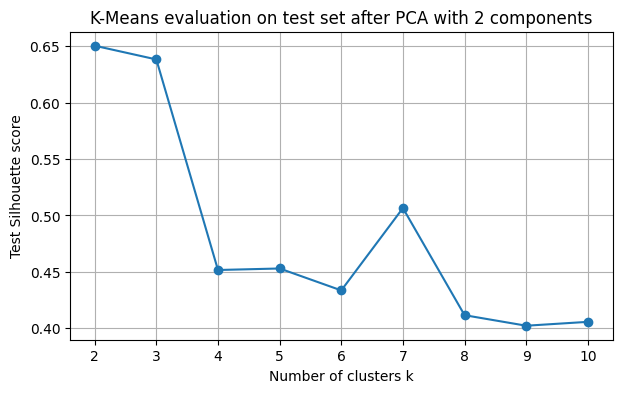

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(results_pca_2["k"], results_pca_2["test_silhouette"], marker="o")
plt.xlabel("Number of clusters k")
plt.ylabel("Test Silhouette score")
plt.title("K-Means evaluation on test set after PCA with 2 components")
plt.grid(True)
plt.show()


## 13. Comparación rápida

Comparamos el mejor resultado usando todas las características con el mejor resultado usando PCA con 2 componentes.


In [ ]:
comparison = pd.DataFrame([
    {
        "Experiment": "All 30 scaled features",
        "PCA components": "No PCA",
        "Best k": int(best_all["k"]),
        "Best test silhouette": float(best_all["test_silhouette"])
    },
    {
        "Experiment": "PCA features",
        "PCA components": 2,
        "Best k": int(best_pca_2["k"]),
        "Best test silhouette": float(best_pca_2["test_silhouette"])
    }
])

comparison


,Experiment,PCA components,Best k,Best test silhouette
0,All 30 scaled features,No PCA,2,0.520267
1,PCA features,2,2,0.650358



# Tarea para el estudiante: clustering con otro dataset médico público

En esta tarea aplicarás el mismo flujo de trabajo a otro dataset relacionado con una enfermedad diferente: el **UCI Heart Disease Dataset**.

**Dataset oficial:** https://archive.ics.uci.edu/dataset/45/heart+disease  
**Enlace directo al archivo usado en Colab:** https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data

Cada fila representa un paciente. El dataset contiene variables clínicas como edad, presión arterial, colesterol, frecuencia cardíaca máxima y otros indicadores cardiovasculares.

Importante: el objetivo de esta tarea no es hacer clasificación supervisada. Usaremos K-Means para hacer **clustering no supervisado**. La columna `target` se conserva solo para interpretar los clústeres al final.



## 14. Cargar el nuevo dataset público

Ejecuta la siguiente celda para descargar el dataset directamente desde UCI y cargarlo en Google Colab.


In [ ]:

# UCI Heart Disease Dataset - Cleveland subset
heart_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

heart_columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal", "target"
]

heart_pd = pd.read_csv(heart_url, names=heart_columns, na_values="?")

print("Original shape:", heart_pd.shape)
print("Missing values per column:")
print(heart_pd.isna().sum())

# For this lab, we remove rows with missing values to keep the task simple
heart_pd = heart_pd.dropna().reset_index(drop=True)

# Optional binary label only for interpretation: 0 = no disease, 1 = presence of disease
heart_pd["target_binary"] = (heart_pd["target"] > 0).astype(int)

print("Shape after removing missing values:", heart_pd.shape)
heart_pd.head()


Original shape: (303, 14)
Missing values per column:
age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          4
thal        2
target      0
dtype: int64
Shape after removing missing values: (297, 15)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target,target_binary
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0,0



## 15. Preparar los datos para clustering

Usa todas las variables clínicas como características de entrada. No uses `target` ni `target_binary` para entrenar K-Means, porque son etiquetas clínicas y K-Means es un método no supervisado.

Pasos obligatorios:

1. Crear el DataFrame de Spark.
2. Construir el vector de características con `VectorAssembler`.
3. Dividir los datos en **80% training** y **20% test**.
4. Ajustar `StandardScaler` solo con el training set.
5. Transformar training y test con el mismo scaler.


In [ ]:
heart_df = spark.createDataFrame(heart_pd)

# Define feature columns, excluding 'target' and 'target_binary'
heart_feature_cols = [
    "age", "sex", "cp", "trestbps", "chol", "fbs", "restecg",
    "thalach", "exang", "oldpeak", "slope", "ca", "thal"
]

heart_assembler = VectorAssembler(
    inputCols=heart_feature_cols,
    outputCol="features_raw"
)

heart_df_features = heart_assembler.transform(heart_df).select("features_raw", "target_binary")

print("Number of features used for clustering:", len(heart_feature_cols))
heart_df_features.show(3, truncate=False)

# Split data into training and test sets
heart_train_df, heart_test_df = heart_df_features.randomSplit([0.8, 0.2], seed=42)

print("Training rows (heart):", heart_train_df.count())
print("Test rows (heart):", heart_test_df.count())

# Standardize features
heart_scaler = StandardScaler(
    inputCol="features_raw",
    outputCol="features",
    withMean=True,
    withStd=True
)

heart_scaler_model = heart_scaler.fit(heart_train_df)
heart_train_scaled = heart_scaler_model.transform(heart_train_df).select("features", "target_binary")
heart_test_scaled = heart_scaler_model.transform(heart_test_df).select("features", "target_binary")

heart_train_scaled.show(3, truncate=False)

Number of features used for clustering: 13
+------------------------------------------------------------+-------------+
|features_raw                                                |target_binary|
+------------------------------------------------------------+-------------+
|[63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0]|0            |
|[67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0]|1            |
|[67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0]|1            |
+------------------------------------------------------------+-------------+
only showing top 3 rows

Training rows (heart): 245
Test rows (heart): 52
+-------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------+-------------+
|features                                                           


## 16. Baseline: K-Means usando todas las características

Primero, aplica K-Means usando las 13 características originales normalizadas. Entrena siempre con el training set y evalúa siempre con el test set.

Tu primer objetivo es encontrar el mejor valor de `k` usando todas las características.


Results using all 13 heart features:


,k,test_silhouette
0,2,0.310111
1,3,0.193321
2,4,0.192524
3,5,0.137151
4,6,0.103239
5,7,0.111918
6,8,0.065423
7,9,0.025971
8,10,0.040483


Best k using all heart features: k = 2, test silhouette = 0.3101


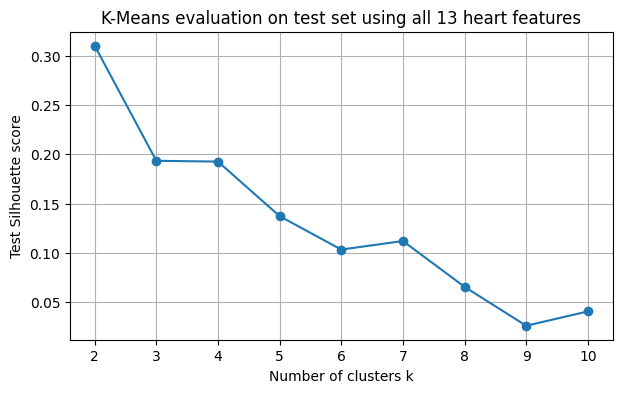

In [ ]:
heart_k_values = range(2, 11)
heart_results_all_features = evaluate_k_values(
    train_data=heart_train_scaled,
    test_data=heart_test_scaled,
    features_col="features",
    k_values=heart_k_values,
    seed=42
)

heart_best_all = heart_results_all_features.loc[heart_results_all_features["test_silhouette"].idxmax()]
print("Results using all 13 heart features:")
display(heart_results_all_features)
print(f"Best k using all heart features: k = {int(heart_best_all['k'])}, test silhouette = {heart_best_all['test_silhouette']:.4f}")

plt.figure(figsize=(7, 4))
plt.plot(heart_results_all_features["k"], heart_results_all_features["test_silhouette"], marker="o")
plt.xlabel("Number of clusters k")
plt.ylabel("Test Silhouette score")
plt.title("K-Means evaluation on test set using all 13 heart features")
plt.grid(True)
plt.show()


## 17. Reducir la dimensionalidad con PCA

Ahora aplicamos PCA para transformar las 13 características originales en un número menor de componentes.

En este ejemplo usamos `k=2` componentes PCA solo para mostrar cómo funciona. Después, en la tarea, deberás probar varios números de componentes.


In [ ]:
pca_2_heart = PCA(
    k=2,
    inputCol="features",
    outputCol="pcaFeatures"
)

pca_2_heart_model = pca_2_heart.fit(heart_train_scaled)
heart_train_pca_2 = pca_2_heart_model.transform(heart_train_scaled).select("pcaFeatures", "target_binary")
heart_test_pca_2 = pca_2_heart_model.transform(heart_test_scaled).select("pcaFeatures", "target_binary")

print("Explained variance ratio for the two PCA components (heart dataset):")
print(pca_2_heart_model.explainedVariance)
print("Total explained variance (heart dataset):", float(sum(pca_2_heart_model.explainedVariance)))

heart_train_pca_2.show(3, truncate=False)


Explained variance ratio for the two PCA components (heart dataset):
[0.24140495750117036,0.12353119364571429]
Total explained variance (heart dataset): 0.36493615114688466
+---------------------------------------+-------------+
|pcaFeatures                            |target_binary|
+---------------------------------------+-------------+
|[2.1415766167719448,1.5016646293007758]|0            |
|[1.7778789762888898,0.3469246353133947]|0            |
|[3.2352279653622023,-1.114725838640236]|0            |
+---------------------------------------+-------------+
only showing top 3 rows




## 18. Encontrar la mejor combinación de PCA y K-Means

Ahora debes completar el análisis principal.

### Qué tienes que probar

Prueba diferentes números de componentes PCA:

```python
pca_components_list = [2, 3, 5, 8, 10]
```

Y diferentes valores de `k`:

```python
k_values = range(2, 11)
```

### Qué tienes que entregar

Debes construir una tabla con estas columnas:

| pca_components | k | test_silhouette | explained_variance |
|---:|---:|---:|---:|

Después, identifica:

1. El mejor número de componentes PCA.
2. El mejor valor de `k`.
3. El mejor Silhouette score en el test set.
4. Si PCA mejora o empeora el resultado respecto al clustering con todas las características.
5. Una explicación breve de por qué puede ocurrir esto.

Recuerda: PCA y K-Means se entrenan con el **training set**, pero la evaluación final se hace con el **test set**.


In [ ]:
pca_components_list = [2, 3, 5, 8, 10]
k_values = range(2, 11)

all_heart_pca_kmeans_results = []

for n_components in pca_components_list:
    print(f"\n--- Processing with {n_components} PCA components ---")

    # Apply PCA
    pca = PCA(
        k=n_components,
        inputCol="features",
        outputCol="pcaFeatures"
    )
    pca_model = pca.fit(heart_train_scaled)
    train_pca = pca_model.transform(heart_train_scaled)
    test_pca = pca_model.transform(heart_test_scaled)
    explained_variance = sum(pca_model.explainedVariance)

    # Evaluate K-Means for various k
    for k in k_values:
        _, _, sil = fit_kmeans_and_evaluate(
            train_data=train_pca,
            test_data=test_pca,
            features_col="pcaFeatures",
            k=k,
            seed=42
        )
        all_heart_pca_kmeans_results.append({
            "pca_components": n_components,
            "k": k,
            "test_silhouette": sil,
            "explained_variance": explained_variance
        })

heart_pca_kmeans_results = pd.DataFrame(all_heart_pca_kmeans_results)

print("\nFull results for PCA and K-Means combinations:")
display(heart_pca_kmeans_results)

best_pca_kmeans = heart_pca_kmeans_results.loc[heart_pca_kmeans_results["test_silhouette"].idxmax()]
print(f"\nBest combination: PCA components = {int(best_pca_kmeans['pca_components'])}, "
      f"k = {int(best_pca_kmeans['k'])}, "
      f"test silhouette = {best_pca_kmeans['test_silhouette']:.4f}")


--- Processing with 2 PCA components ---

--- Processing with 3 PCA components ---

--- Processing with 5 PCA components ---

--- Processing with 8 PCA components ---

--- Processing with 10 PCA components ---

Full results for PCA and K-Means combinations:


,pca_components,k,test_silhouette,explained_variance
0,2,2,0.584483,0.364936
1,2,3,0.557163,0.364936
2,2,4,0.499902,0.364936
3,2,5,0.481753,0.364936
4,2,6,0.419320,0.364936
5,2,7,0.506897,0.364936
6,2,8,0.375008,0.364936
7,2,9,0.437815,0.364936
8,2,10,0.471264,0.364936
9,3,2,0.504473,0.460227



Best combination: PCA components = 2, k = 2, test silhouette = 0.5845



## 19. Comparar todas las características vs. PCA

Usa esta comparación para responder si PCA ha mejorado la calidad del clustering en el test set.


In [ ]:
comparison_heart = pd.DataFrame([
    {
        "Experiment": "All 13 scaled features",
        "PCA components": "No PCA",
        "Best k": int(heart_best_all["k"]),
        "Best test silhouette": float(heart_best_all["test_silhouette"])
    },
    {
        "Experiment": "PCA features",
        "PCA components": int(best_pca_kmeans["pca_components"]),
        "Best k": int(best_pca_kmeans["k"]),
        "Best test silhouette": float(best_pca_kmeans["test_silhouette"])
    }
])

display(comparison_heart)

,Experiment,PCA components,Best k,Best test silhouette
0,All 13 scaled features,No PCA,2,0.310111
1,PCA features,2,2,0.584483


In [ ]:

# your code



## 20. Interpretación opcional de los clústeres

Aunque K-Means no usa la columna `target_binary`, puedes comparar los clústeres con esta columna para interpretar si los grupos encontrados tienen alguna relación con la presencia o ausencia de enfermedad cardíaca.

Este análisis es solo interpretativo. No convierte el problema en clasificación supervisada.


In [ ]:
# Extract best parameters
best_n_components = int(best_pca_kmeans['pca_components'])
best_k = int(best_pca_kmeans['k'])

print(f"Interpreting clusters for best combination: {best_n_components} PCA components, k = {best_k}")

# Re-apply PCA with the best number of components
pca_final = PCA(
    k=best_n_components,
    inputCol="features",
    outputCol="pcaFeatures"
)
pca_final_model = pca_final.fit(heart_train_scaled)
train_pca_final = pca_final_model.transform(heart_train_scaled).select("pcaFeatures", "target_binary")
test_pca_final = pca_final_model.transform(heart_test_scaled).select("pcaFeatures", "target_binary")

# Fit K-Means with the best k on the PCA-transformed training data
kmeans_final = KMeans(
    featuresCol="pcaFeatures",
    predictionCol="prediction",
    k=best_k,
    seed=42
)
kmeans_final_model = kmeans_final.fit(train_pca_final)

# Get predictions on the PCA-transformed test data
test_predictions_final = kmeans_final_model.transform(test_pca_final)

Interpreting clusters for best combination: 2 PCA components, k = 2



## Respuestas del estudiante

Escribe aquí tus respuestas finales:

1. Mejor valor de `k` usando todas las características:  
2. Mejor Silhouette score usando todas las características:  
3. Mejor número de componentes PCA:  
4. Mejor valor de `k` después de PCA:  
5. Mejor Silhouette score después de PCA:  
6. ¿PCA mejora o empeora el clustering respecto a usar todas las características?  
7. ¿Qué ocurre cuando usamos muy pocos componentes PCA?  
8. ¿Los clústeres parecen estar relacionados con la presencia o ausencia de enfermedad cardíaca? Justifica brevemente.


## 21. Detener Spark

Ejecuta esta celda al final si quieres cerrar la sesión de Spark.


In [ ]:
spark.stop()
